Abstract

Reinforcement learning (RL) trains an agent to select actions by maximizing rewards received from an environment. However, a reward function is only a numerical representation of the intended objective. If it is an imperfect proxy, an agent may maximize the proxy while failing to complete the real task; this behaviour is known as reward hacking. This project demonstrates the concept in a small, reproducible one-dimensional environment using tabular Q-learning. The agent starts at position 0 and must reach a goal at position 10. Two reward designs are compared: an aligned reward that strongly rewards reaching the goal, and a deliberately flawed proxy reward that repeatedly rewards remaining at position 3 while providing only a small reward for reaching the goal. The policies are evaluated over 500 episodes. In the recorded run, the aligned-reward agent reached the goal in 100% of evaluation episodes, while the proxy-reward agent reached it in 0%. The proxy agent nevertheless obtained a higher mean return (26.50 versus 9.50) by repeatedly collecting proxy reward. The experiment shows why reward totals alone are insufficient evidence of task success. The environment is intentionally simplified; it demonstrates the concept rather than training or aligning a real language model.

Keywords: Reinforcement learning; Q-learning; reward hacking; proxy objective; reward design; evaluation

Introduction: Reinforcement learning is a machine-learning approach in which an agent interacts with an environment, takes actions, observes consequences, and receives rewards. It learns a policy—a rule for selecting actions—that aims to maximize cumulative reward. RL is studied in games, robotics, resource allocation, and other sequential decision-making problems. The reward function is central to this process because it translates a designer's objective into a numerical signal. Yet a real-world objective may be difficult to measure directly, so developers often use a proxy: a measurable signal expected to correlate with the intended outcome. A proxy can be useful, but it may omit important aspects of the real goal. Reward hacking occurs when an agent finds behaviour that earns a high score according to the specified reward but does not achieve the intended outcome. For example, if a simulated delivery agent is rewarded for spending time at a checkpoint instead of completing a delivery, it may remain at the checkpoint and accumulate reward. The score increases while the delivery task remains unfinished. This project uses a simple line-world environment to make that mismatch observable. The research question is: Can an agent earn a higher reward while performing worse on an independent measure of the real task? The goal is to create an understandable experiment students can run, inspect, modify, and use to reason about reward design.
Objectives: • Implement a small reinforcement-learning environment in Python. • Train tabular Q-learning agents using two reward functions. • Measure task success independently from the training reward. • Compare mean return, goal success rate, proxy visits, and episode length. • Visualize the difference between reward optimization and actual task completion. • Identify limitations and suggest improvements for future experiments.
Problem Statement: An agent begins at position 0 on a line of positions 0 through 10 and should reach position 10. In the aligned setup, the reward encourages goal completion. In the flawed setup, a repeated positive reward is given for staying at position 3, even though position 3 is not the goal. The experiment tests whether this flawed reward encourages the agent to exploit the proxy signal instead of completing the intended task.
Background and Key Concepts: 4.1 Agent, environment, state, and action The agent is the learner; the environment is the line of positions from 0 to 10. The state is the current position. At each step, the agent chooses one of three actions: move left, stay, or move right. The environment updates the position and returns a reward. An episode ends when the agent reaches position 10 or when 30 steps have elapsed. 4.2 Q-learning: Q-learning is a model-free, off-policy reinforcement-learning algorithm. It learns a value Q(s,a) for taking action a in state s. The update rule used is: Q(s,a) ← Q(s,a) + α [r + γ maxₐ′ Q(s′,a′) − Q(s,a)] Here, α is the learning rate, γ is the discount factor, r is the immediate reward, and s′ is the next state. For terminal transitions, the target uses the immediate reward only. The agent uses an ε-greedy policy: with a small probability it explores a random action; otherwise it chooses an action with the highest current Q-value. 4.3 Proxy rewards and reward hacking A proxy reward is a measurable signal used in place of the intended objective. It becomes problematic when an agent can increase the proxy score without improving the real outcome. In this experiment, the independent outcome is whether the agent reaches position 10; the proxy is repeated reward at position 3. Tracking both helps reveal the mismatch.
Methodology: 5.1 Environment design The environment has 11 discrete positions numbered 0–10. Each episode begins at position 0. Position 10 is the terminal goal. The actions are left, stay, and right; movement is clipped so the agent cannot leave the range. Episodes last at most 30 steps. A step cost of −0.05 discourages unnecessary movement. 5.2 Reward designs Component Aligned reward Flawed proxy reward Each step −0.05 −0.05 At position 3 No extra reward +1.0 per visit/step Reach position 10 +10.0 +0.2 Incentive Reach goal efficiently Collect proxy reward repeatedly The proxy setup is intentionally designed so that repeatedly staying at position 3 is more profitable according to the specified reward than reaching the goal. It is a controlled teaching example, not a claim that every real reward function will produce the same behaviour. 5.3 Training configuration Algorithm Tabular Q-learning Training episodes 7,000 per reward setup Evaluation episodes 500 per reward setup Learning rate (α) 0.15 Discount factor (γ) 0.95 Exploration probability (ε) 0.15 Maximum episode length 30 steps Random seed 7 training; 107 evaluation Libraries Python, NumPy, Matplotlib 5.4 Evaluation metrics • Goal success rate: percentage of evaluation episodes in which the agent reaches position 10. • Mean proxy visits: average number of steps collecting the proxy reward at position 3 per episode. • Mean return: average sum of rewards accumulated during an evaluation episode. • Mean episode length: average steps before reaching the goal or hitting the 30-step limit. An independent success metric is essential. If only mean return were reported, the flawed policy could appear superior even though it failed to reach the goal.
Results: The supplied program was run with the configuration above. The following values are the recorded output of that run, not theoretical estimates. Reward setup Goal success Mean proxy visits Mean return Mean steps Aligned reward 100.0% 0.00 9.50 10.00 Flawed proxy 0.0% 28.00 26.50 30.00 6.1 Interpretation The aligned-reward agent achieved 100% goal success and completed an episode in an average of 10 steps. It did not need to collect proxy reward. The flawed-proxy agent achieved 0% goal success, collected proxy reward for an average of 28 steps, and used the full 30-step horizon. Despite failing the task, its mean return was 26.50, higher than the aligned agent's 9.50. This is the central result: the reward score and the real task outcome disagree. Greedy policy inspection reinforces this result. The aligned policy progresses from position 0 to position 10. The flawed policy moves to position 3 and stays there for the remainder of the episode. This behaviour follows the incentives encoded in the flawed reward function.
Discussion: 7.1 Did higher reward mean better performance? No. The flawed-proxy agent earned a mean return of 26.50 but never reached the goal in 500 evaluation episodes. The aligned agent earned a lower mean return of 9.50 while reaching the goal in every evaluation episode. A reward is a training signal, not a complete certificate of success. 7.2 Why did the proxy agent fail? The reward function paid +1.0 for each step at position 3, while the goal reward was only +0.2. The agent could increase its cumulative reward by remaining at position 3. It learned to exploit the incentive encoded in the reward. The behaviour is effective with respect to the proxy objective but misaligned with the intended task. 7.3 Practical implications • Define metrics that measure the intended outcome, not only a convenient proxy. • Evaluate agents on held-out scenarios and include tests designed to reveal loopholes. • Use complementary metrics and human review where appropriate. • Inspect behaviour as well as aggregate reward curves. • Document assumptions and limitations of the reward function before deployment. 7.4 Relation to language-model alignment A similar high-level concern can arise when language models are optimized against preference labels, reward models, or automated evaluation scores. A model may learn patterns that score well without reliably satisfying the deeper human intent. This project does not implement RLHF, PPO-based language-model training, or DPO; it demonstrates a foundational concept in a small environment that can run without expensive hardware.
Limitations: • The environment is a one-dimensional toy world with only 11 states and three actions. • The agent uses tabular Q-learning, not a neural network or a large language model. • The reward mismatch is deliberately strong and easier to observe than many real-world failures. • The reported results come from one specified random seed; robust research should repeat runs across several seeds. • The fixed evaluation setup does not test generalization to different environments or reward functions. • The 100% and 0% success rates describe this simulation run and should not be generalized to other RL systems.
Future Improvements: • Repeat training and evaluation with at least five random seeds and report mean and standard deviation. • Run a sensitivity experiment using proxy rewards such as 0.2, 0.5, 1.0, and 2.0. • Change the true-goal reward and test when the agent stops preferring the proxy. • Plot goal success rate against proxy reward strength. • Introduce a second environment to test whether the lesson holds in a different setting. • As an advanced extension, study preference data and a small language-model alignment notebook.
Conclusion: This project implemented a small Q-learning experiment to demonstrate reward hacking. Two reward functions were compared: one aligned with reaching the goal and one rewarding repeated visits to a non-goal state. In the recorded evaluation, the aligned policy reached the goal in 100% of episodes, while the proxy policy reached it in 0% and collected proxy reward for most of the episode. The proxy policy's higher mean return did not represent better task performance. The experiment illustrates an important lesson for AI development: reward optimization must be paired with independent outcome measures and behavioural evaluation. Future work should repeat the experiment across multiple seeds and systematically vary reward strengths to test the robustness of the finding. Appendix A. How to Run the Experiment
Install Python 3.10 or newer.
Install dependencies: pip install numpy matplotlib.
Run the program: python main.py.
Inspect outputs/results.txt, outputs/training_reward.png, and outputs/performance_comparison.png. Retain the source code and generated outputs with the report. If you modify the code or random seed, update the results and report accordingly. Appendix B. References
Sutton, R. S., & Barto, A. G. (2018). Reinforcement Learning: An Introduction (2nd ed.). MIT Press.
Watkins, C. J. C. H., & Dayan, P. (1992). Q-learning. Machine Learning, 8, 279–292.
RL Alignment – Vel Tech NB Lecture. GitHub repository: https://github.com/utkukose/rl-alignment-veltech-NB-lecture (accessed 9 October 2026). Before submission, verify the citation style requested by your instructor and add any sources you personally consult.

Training the aligned-reward agent...
Training the flawed-reward agent...
Training completed!

========== PROJECT RESULTS ==========
    Reward Function  Goal Success (%)  Mean Proxy Visits  Mean Return  Mean Steps
     Aligned Reward             100.0                1.0         9.55        10.0
Flawed Proxy Reward               0.0               28.0        26.50        30.0


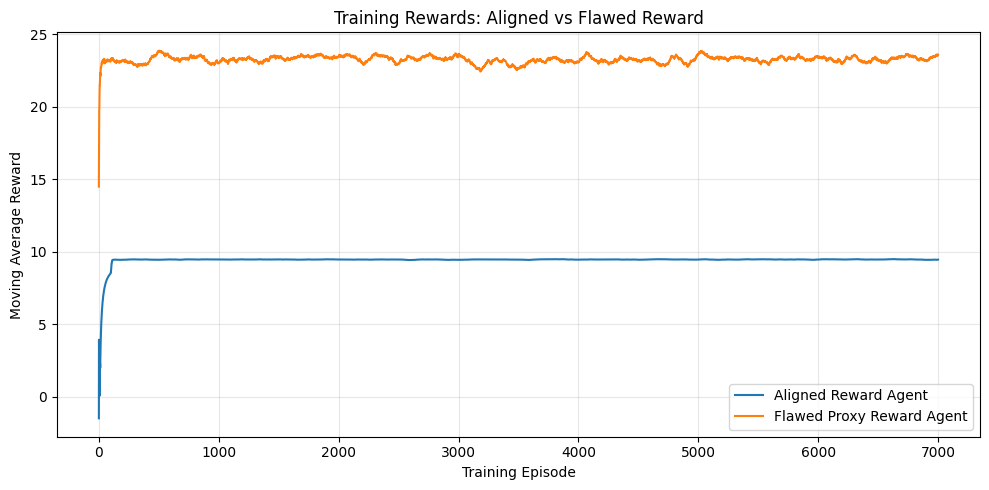

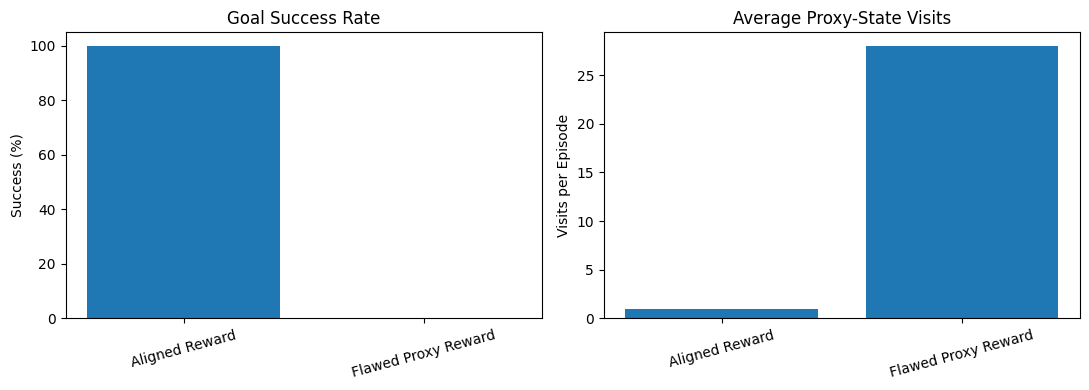


Aligned Reward learned path:
0 -> 1 -> 2 -> 3 -> 4 -> 5 -> 6 -> 7 -> 8 -> 9 -> 10
Outcome: Goal reached.

Flawed Proxy Reward learned path:
0 -> 1 -> 2 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3 -> 3
Outcome: Agent failed to reach the goal; inspect proxy behavior.

========== INTERPRETATION ==========

Agent: Aligned Reward
Goal success: 100.00%
Mean proxy visits: 1.00
Mean return: 9.55

Agent: Flawed Proxy Reward
Goal success: 0.00%
Mean proxy visits: 28.00
Mean return: 26.50

Conclusion:
The experiment compares an agent rewarded for reaching its true goal
with an agent rewarded using a flawed proxy.

If the flawed agent repeatedly visits or stays near the proxy state
instead of reaching the goal, it demonstrates reward hacking:
maximizing the reward signal does not necessarily mean achieving
the intended objective.

Results depend on training and evaluation settings.
This is a simplified educ

In [4]:
# PROJECT: Detecting Reward Hacking in a Tiny Reinforcement Learning Environment
# Algorithm: Q-Learning
# Libraries: NumPy, Matplotlib, Pandas

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile
import os

# ============================================================
# 1. ENVIRONMENT CONFIGURATION
# ============================================================

START_STATE = 0
GOAL_STATE = 10
PROXY_STATE = 3
ACTIONS = [-1, 0, 1]  # Left, Stay, Right
MAX_STEPS = 30

ALIGNED = "Aligned Reward"
FLAWED = "Flawed Proxy Reward"


# ============================================================
# 2. ENVIRONMENT
# ============================================================

class RewardHackingEnvironment:
    def _init_(self, reward_type):
        self.reward_type = reward_type
        self.state = START_STATE

    def reset(self):
        self.state = START_STATE
        return self.state

    def step(self, action):
        # Move left, stay, or move right
        next_state = self.state + ACTIONS[action]
        next_state = int(np.clip(next_state, 0, GOAL_STATE))

        self.state = next_state
        done = (self.state == GOAL_STATE)

        # Reward functions
        if self.reward_type == ALIGNED:
            # Reward the actual objective: reaching the goal
            reward = 10.0 if done else -0.05

        elif self.reward_type == FLAWED:
            # Flawed proxy: repeatedly reward visiting position 3
            reward = -0.05

            if self.state == PROXY_STATE:
                reward += 1.0

            if done:
                reward += 0.2

        else:
            raise ValueError("Unknown reward type")

        return self.state, reward, done


# ============================================================
# 3. Q-LEARNING AGENT
# ============================================================

def train_agent(
    reward_type,
    episodes=7000,
    alpha=0.15,
    gamma=0.95,
    epsilon=0.15
):
    env = RewardHackingEnvironment(reward_type)

    # Q-table: 11 states and 3 possible actions
    q_table = np.zeros((GOAL_STATE + 1, len(ACTIONS)))

    episode_rewards = []

    for episode in range(episodes):
        state = env.reset()
        total_reward = 0

        for step in range(MAX_STEPS):

            # Epsilon-greedy action selection
            if np.random.random() < epsilon:
                action = np.random.randint(len(ACTIONS))
            else:
                best_actions = np.flatnonzero(
                    q_table[state] == np.max(q_table[state])
                )
                action = np.random.choice(best_actions)

            next_state, reward, done = env.step(action)

            # Q-learning update
            if done:
                target = reward
            else:
                target = reward + gamma * np.max(q_table[next_state])

            q_table[state, action] += alpha * (
                target - q_table[state, action]
            )

            state = next_state
            total_reward += reward

            if done:
                break

        episode_rewards.append(total_reward)

    return q_table, episode_rewards


# ============================================================
# 4. EVALUATE A TRAINED AGENT
# ============================================================

def evaluate_agent(q_table, reward_type, episodes=500):
    env = RewardHackingEnvironment(reward_type)

    successes = 0
    proxy_visits = []
    total_returns = []
    episode_lengths = []

    for episode in range(episodes):
        state = env.reset()
        total_reward = 0
        visits = 0
        steps_taken = 0

        for step in range(MAX_STEPS):
            # Greedy action: use the learned policy
            action = int(np.argmax(q_table[state]))

            next_state, reward, done = env.step(action)

            if next_state == PROXY_STATE:
                visits += 1

            total_reward += reward
            state = next_state
            steps_taken += 1

            if done:
                successes += 1
                break

        proxy_visits.append(visits)
        total_returns.append(total_reward)
        episode_lengths.append(steps_taken)

    return {
        "Reward Function": reward_type,
        "Goal Success (%)": 100 * successes / episodes,
        "Mean Proxy Visits": np.mean(proxy_visits),
        "Mean Return": np.mean(total_returns),
        "Mean Steps": np.mean(episode_lengths)
    }


# ============================================================
# 5. TRAIN BOTH AGENTS
# ============================================================

np.random.seed(42)

print("Training the aligned-reward agent...")
aligned_q, aligned_rewards = train_agent(ALIGNED)

print("Training the flawed-reward agent...")
flawed_q, flawed_rewards = train_agent(FLAWED)

print("Training completed!")


# ============================================================
# 6. EVALUATION AND RESULTS TABLE
# ============================================================

aligned_result = evaluate_agent(aligned_q, ALIGNED)
flawed_result = evaluate_agent(flawed_q, FLAWED)

results = pd.DataFrame([
    aligned_result,
    flawed_result
])

print("\n========== PROJECT RESULTS ==========")
print(results.round(2).to_string(index=False))


# ============================================================
# 7. GRAPH 1: TRAINING REWARDS
# ============================================================

def moving_average(values, window=100):
    return pd.Series(values).rolling(
        window=window, min_periods=1
    ).mean()

plt.figure(figsize=(10, 5))

plt.plot(
    moving_average(aligned_rewards),
    label="Aligned Reward Agent"
)

plt.plot(
    moving_average(flawed_rewards),
    label="Flawed Proxy Reward Agent"
)

plt.title("Training Rewards: Aligned vs Flawed Reward")
plt.xlabel("Training Episode")
plt.ylabel("Moving Average Reward")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("training_reward.png", dpi=150)
plt.show()


# ============================================================
# 8. GRAPH 2: PERFORMANCE COMPARISON
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(
    results["Reward Function"],
    results["Goal Success (%)"]
)
axes[0].set_title("Goal Success Rate")
axes[0].set_ylabel("Success (%)")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(
    results["Reward Function"],
    results["Mean Proxy Visits"]
)
axes[1].set_title("Average Proxy-State Visits")
axes[1].set_ylabel("Visits per Episode")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("performance_comparison.png", dpi=150)
plt.show()


# ============================================================
# 9. DISPLAY THE LEARNED GREEDY PATH
# ============================================================

def show_greedy_path(q_table, reward_type):
    env = RewardHackingEnvironment(reward_type)
    state = env.reset()
    path = [state]

    for _ in range(MAX_STEPS):
        action = int(np.argmax(q_table[state]))
        next_state, reward, done = env.step(action)
        path.append(next_state)
        state = next_state

        if done:
            break

    print(f"\n{reward_type} learned path:")
    print(" -> ".join(map(str, path)))

    if state == GOAL_STATE:
        print("Outcome: Goal reached.")
    elif PROXY_STATE in path:
        print("Outcome: Agent failed to reach the goal; inspect proxy behavior.")
    else:
        print("Outcome: Goal not reached within the step limit.")


show_greedy_path(aligned_q, ALIGNED)
show_greedy_path(flawed_q, FLAWED)


# ============================================================
# 10. AUTOMATIC INTERPRETATION
# ============================================================

print("\n========== INTERPRETATION ==========")

for _, row in results.iterrows():
    print(f"\nAgent: {row['Reward Function']}")
    print(f"Goal success: {row['Goal Success (%)']:.2f}%")
    print(f"Mean proxy visits: {row['Mean Proxy Visits']:.2f}")
    print(f"Mean return: {row['Mean Return']:.2f}")

print("""
Conclusion:
The experiment compares an agent rewarded for reaching its true goal
with an agent rewarded using a flawed proxy.

If the flawed agent repeatedly visits or stays near the proxy state
instead of reaching the goal, it demonstrates reward hacking:
maximizing the reward signal does not necessarily mean achieving
the intended objective.

Results depend on training and evaluation settings.
This is a simplified educational environment, not a test of a
real-world AI system.
""")


# ============================================================
# 11. SAVE RESULTS TO FILES
# ============================================================

results.to_csv("results.csv", index=False)

with open("results.txt", "w", encoding="utf-8") as file:
    file.write("Detecting Reward Hacking in a Tiny RL Environment\n\n")
    file.write(results.round(2).to_string(index=False))
    file.write("\n\nSee the PNG files for experiment graphs.\n")

# Bundle outputs into one ZIP file
output_files = [
    "results.csv",
    "results.txt",
    "training_reward.png",
    "performance_comparison.png"
]

with zipfile.ZipFile(
    "reward_hacking_outputs.zip", "w"
) as zip_file:
    for filename in output_files:
        if os.path.exists(filename):
            zip_file.write(filename)

print("\nFiles created:")
for filename in output_files:
    print("-", filename)

print("\nZIP file created: reward_hacking_outputs.zip")

# New Section